In [1]:
# SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
# SPDX-License-Identifier: Apache-2.0
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# FLUX.2 [klein] 4B Pipeline Optimized with <span style='color: #76B900'>TensorRT-RTX</span>

In [2]:
import gc
import io
import logging
import os
import sys
import warnings
from dataclasses import dataclass, replace
from pathlib import Path
from typing import Optional

import torch

# Resolves tqdm import issue on Windows
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# Add demo/flux2/ to the current path when running in VS Code
if "__session__" in locals():
    sys.path.append(str(Path(os.path.realpath(__session__)).parent))  # noqa: F821

from diffusers.utils import logging as diffusers_logging
from flux2_pipeline import Flux2FP8TorchTensorRTPipeline
from IPython.display import Image, Markdown, display
from transformers.utils import logging as transformers_logging

# Silence third-party deprecation and optional-dependency notices that are not actionable in this demo
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=r"transformers .* is not tested with current version of modelopt")
diffusers_logging.set_verbosity_error()
transformers_logging.set_verbosity_error()
for logger_name in ("torch._library", "torch._opaque_base", "torch_tensorrt"):
    logging.getLogger(logger_name).setLevel(logging.ERROR)

In [3]:
DEMO_CACHE_DIR = "./demo_cache/"  # Where the model weights, engines, runtime cache, and images will be stored
HF_TOKEN = None  # Optional HuggingFace token; the FLUX.2 [klein] 4B models are not gated
DEVICE = "cuda"

## Demo Helper Functions


In [4]:
def printmd(string: str):
    """Display markdown text in the notebook."""
    display(Markdown(string))


def markdown_bold_green_format(string: str) -> str:
    """Format string as bold green markdown."""
    return f"<span style='color: #76B900; font-weight: bold'>{string}</span>"


def gpu_memory_used_gb() -> float:
    """Device-wide GPU memory in use, after releasing PyTorch's cached free blocks. Includes other processes."""
    gc.collect()
    torch.cuda.empty_cache()
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    return (total_bytes - free_bytes) / 1024**3


@dataclass
class GenerationConfig:
    """Configuration for image generation parameters."""
    height: int = 1024
    width: int = 1024
    batch_size: int = 1
    seed: int = 0
    num_inference_steps: int = 4
    prompt: str = "A cinematic photograph of an astronaut riding a horse on Mars"


pipeline = None


def prepare_pipeline(
    config: GenerationConfig,
    enable_runtime_cache: bool = True,
    enable_engine_cache: bool = False,
    weight_streaming_budget: Optional[float] = None,
) -> tuple[Flux2FP8TorchTensorRTPipeline, dict]:
    """
    Load FLUX.2 [klein] 4B and compile its FP8 transformer with Torch-TensorRT-RTX for the shape in `config`.

    Any previously prepared pipeline is released first, so only one transformer engine occupies GPU memory
    and its runtime cache is saved to disk.

    Args:
        config: GenerationConfig with image parameters
        enable_runtime_cache: Reuse TensorRT-RTX JIT-compiled kernels across runs
        enable_engine_cache: Reuse built TensorRT-RTX engines across runs
        weight_streaming_budget: Fraction [0, 1] of streamable transformer weights kept in GPU memory;
            0 streams the most weights, or None to disable weight streaming

    Returns:
        (pipeline, compile_times_dict)
    """
    global pipeline
    if pipeline is not None:
        pipeline.cleanup()
        pipeline = None
        gc.collect()
        torch.cuda.empty_cache()

    features = []
    if enable_runtime_cache:
        features.append("**Runtime Cache**")
    if enable_engine_cache:
        features.append("**Engine Cache**")
    if weight_streaming_budget is not None:
        features.append(f"**Weight Streaming** ({weight_streaming_budget:.0%} budget)")
    mode_desc = f" with {' + '.join(features)}" if features else ""
    printmd(
        f"Initializing FLUX.2 [klein] 4B with an FP8 {markdown_bold_green_format('TensorRT-RTX')} "
        f"transformer{mode_desc}..."
    )

    pipeline = Flux2FP8TorchTensorRTPipeline(
        cache_dir=DEMO_CACHE_DIR,
        device=DEVICE,
        hf_token=HF_TOKEN,
        enable_engine_cache=enable_engine_cache,
        enable_runtime_cache=enable_runtime_cache,
    )
    printmd("**Loading the Diffusers pipeline**...")
    pipeline.load()

    printmd("**Exporting and compiling the transformer**...")
    compile_times = pipeline.compile_transformer(
        batch_size=config.batch_size,
        height=config.height,
        width=config.width,
        weight_streaming_budget=weight_streaming_budget,
    )
    printmd(f"**Step 1** `torch.export` time: {compile_times['export']:.2f} seconds")
    printmd(f"**Step 2** `torch_tensorrt.dynamo.compile` time: {compile_times['compile']:.2f} seconds")
    printmd(
        markdown_bold_green_format("JIT Compilation")
        + f" + first transformer execution time: {compile_times['jit']:.2f} seconds"
    )
    if pipeline.weight_streaming is not None:
        printmd(
            f"**Weight streaming**: {pipeline.weight_streaming['device_budget_bytes'] / 1024**3:.2f} GiB of "
            f"{pipeline.weight_streaming['total_streamable_bytes'] / 1024**3:.2f} GiB of transformer weights kept on the GPU"
        )
    return pipeline, compile_times


def generate(pipeline: Flux2FP8TorchTensorRTPipeline, config: GenerationConfig) -> float:
    """Generate and display images. Returns the end-to-end generation time in seconds."""
    shape = pipeline.compiled_shape
    if shape is None:
        raise RuntimeError("Call compile_transformer() before generate()")
    printmd(f"**Prompt**: {config.prompt}\n")
    print(
        f"[I] Starting image generation with dimensions: {shape.width} x {shape.height} "
        f"and {config.num_inference_steps} denoising iterations"
    )
    print(f"[I] Using seed {config.seed}")

    images, seconds = pipeline.infer(
        prompt=config.prompt,
        num_inference_steps=config.num_inference_steps,
        seed=config.seed,
        save_dir=DEMO_CACHE_DIR,
    )
    printmd(f"**Generated Image(s) in {seconds:.2f}s**")
    for image in images:
        # Display a half-resolution preview; the full-resolution image is saved in DEMO_CACHE_DIR
        preview = io.BytesIO()
        image.resize((image.width // 2, image.height // 2)).save(preview, format="JPEG", quality=90)
        display(Image(data=preview.getvalue(), format="jpeg"))
    return seconds

# 1. Quickstart

### Overview
We provide a demonstration of running FLUX.2 [klein] 4B with its pre-quantized FP8 transformer accelerated by <span style='color: #76B900'>TensorRT-RTX</span> through [Torch-TensorRT-RTX](https://pypi.org/project/torch-tensorrt-rtx/). The FP8 checkpoint is loaded into a [ModelOpt](https://github.com/NVIDIA/TensorRT-Model-Optimizer)-quantized Diffusers transformer, which is compiled directly in two explicit steps:

1. `torch.export.export` captures the transformer as an `ExportedProgram`, with ModelOpt emitting its FP8 quantizers as TensorRT quantize and dequantize operations.
2. `torch_tensorrt.dynamo.compile` converts the exported graph into a single <span style='color: #76B900'>TensorRT-RTX</span> engine that runs the quantized layers as FP8 matrix multiplications.

The compiled transformer is then swapped into an otherwise unmodified Diffusers `Flux2KleinPipeline`, so the Qwen3 text encoder, scheduler, and VAE continue to run in PyTorch. FLUX.2 [klein] is step-distilled and generates images in 4 denoising steps.

> **Note:** This end-to-end notebook was verified on an NVIDIA GeForce RTX 5090 (Blackwell) GPU. FP8 requires an Ada or Blackwell GPU. See `demo/flux2/README.md` for installation instructions.

#### Features Highlighted

1. **Two-Step Compilation**: Compile a quantized PyTorch model ahead of time into a <span style='color: #76B900'>TensorRT-RTX</span> engine and use it as a drop-in replacement
2. **FP8 Quantization**: Run a pre-quantized FP8 checkpoint with FP8 matrix multiplications
3. **JIT Compilation**: Specializes the <span style='color: #76B900'>TensorRT-RTX</span> engine to the GPU on which you are running inference
4. **Runtime Caching**: Faster JIT times through caching kernel compilations
5. **Engine Caching**: Skip engine builds by reusing and refitting cached engines
6. **Weight Streaming**: Reduce GPU memory usage by streaming weights from host memory

## Model Configuration

In [5]:
config = GenerationConfig(
    height=1024,
    width=1024,
    batch_size=1,
    seed=0,
    num_inference_steps=4,
    prompt="A cinematic photograph of an astronaut riding a horse on Mars",
)

## Pipeline Initialization

In [6]:
pipeline, initial_compile_times = prepare_pipeline(
    config=config,
    enable_runtime_cache=True,
)

Initializing FLUX.2 [klein] 4B with an FP8 <span style='color: #76B900; font-weight: bold'>TensorRT-RTX</span> transformer with **Runtime Cache**...

**Loading the Diffusers pipeline**...

Inserted 409 quantizers


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

**Exporting and compiling the transformer**...

  0%|          | 0/1 [00:00<?, ?it/s]

Loading extension modelopt_cuda_ext_fp8...


**Step 1** `torch.export` time: 2.18 seconds

**Step 2** `torch_tensorrt.dynamo.compile` time: 34.53 seconds

<span style='color: #76B900; font-weight: bold'>JIT Compilation</span> + first transformer execution time: 4.04 seconds

**Compiled** with <span style='color: #76B900; font-weight: bold'>TensorRT-RTX</span> and Transformer in **FP8** Precision


**Prompt**: A cinematic photograph of an astronaut riding a horse on Mars


[I] Starting image generation with dimensions: 1024 x 1024 and 4 denoising iterations
[I] Using seed 0


  0%|          | 0/4 [00:00<?, ?it/s]

**Generated Image(s) in 0.61s**

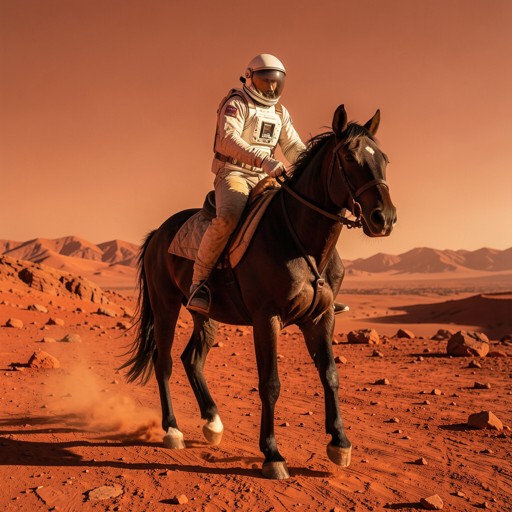

In [7]:
printmd(f"**Compiled** with {markdown_bold_green_format('TensorRT-RTX')} and Transformer in **FP8** Precision\n")
quickstart_seconds = generate(pipeline, config)
quickstart_memory_gb = gpu_memory_used_gb()

## Reusing the Engine for New Prompts
The engine is specialized to the image shape (height, width, and batch size), not to the prompt. Any prompt with the same shape reuses the engine without recompiling:

**Prompt**: A lighthouse on a rocky coast at dawn, oil painting


[I] Starting image generation with dimensions: 1024 x 1024 and 4 denoising iterations
[I] Using seed 7


  0%|          | 0/4 [00:00<?, ?it/s]

**Generated Image(s) in 0.55s**

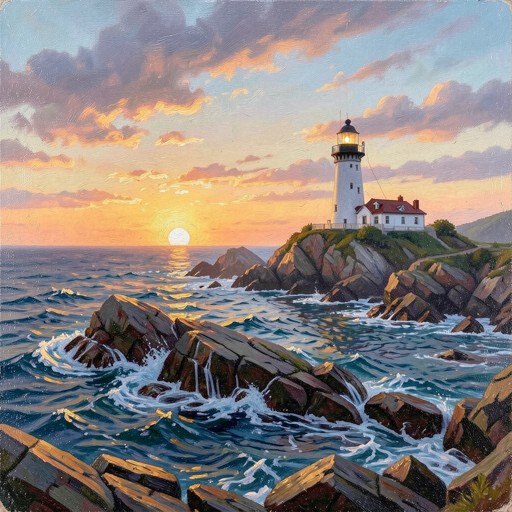

0.5511125409975648

In [8]:
generate(pipeline, replace(config, prompt="A lighthouse on a rocky coast at dawn, oil painting", seed=7))

# 2. Runtime Caching
<span style='color: #76B900'>TensorRT-RTX</span> compiles kernels specialized for your GPU the first time an engine runs. _Runtime Caching_ serializes these JIT-compiled kernels to disk, so later runs of the same engine skip most of the JIT work. Here, we rebuild the pipeline and feature the JIT-time improvement from the runtime cache populated in the Quickstart.

> **Note:** The runtime cache is stored in `DEMO_CACHE_DIR/runtime.cache`. Delete it to observe cold JIT times again.

In [9]:
pipeline, rt_cache_compile_times = prepare_pipeline(
    config=config,
    enable_runtime_cache=True,  #### Runtime cache populated in the Quickstart ####
)

printmd(
    markdown_bold_green_format("Runtime Cache JIT Compilation")
    + f" + first transformer execution time: {rt_cache_compile_times['jit']:.2f} seconds, "
    f"a **{initial_compile_times['jit'] / rt_cache_compile_times['jit']:.2f}x** Improvement"
)

Initializing FLUX.2 [klein] 4B with an FP8 <span style='color: #76B900; font-weight: bold'>TensorRT-RTX</span> transformer with **Runtime Cache**...

**Loading the Diffusers pipeline**...

Inserted 409 quantizers


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

**Exporting and compiling the transformer**...

  0%|          | 0/1 [00:00<?, ?it/s]

**Step 1** `torch.export` time: 2.32 seconds

**Step 2** `torch_tensorrt.dynamo.compile` time: 34.82 seconds

<span style='color: #76B900; font-weight: bold'>JIT Compilation</span> + first transformer execution time: 0.30 seconds

<span style='color: #76B900; font-weight: bold'>Runtime Cache JIT Compilation</span> + first transformer execution time: 0.30 seconds, a **13.25x** Improvement

**Prompt**: A cat meanders down a dimly lit alleyway in a large city.


[I] Starting image generation with dimensions: 1024 x 1024 and 4 denoising iterations
[I] Using seed 3


  0%|          | 0/4 [00:00<?, ?it/s]

**Generated Image(s) in 0.56s**

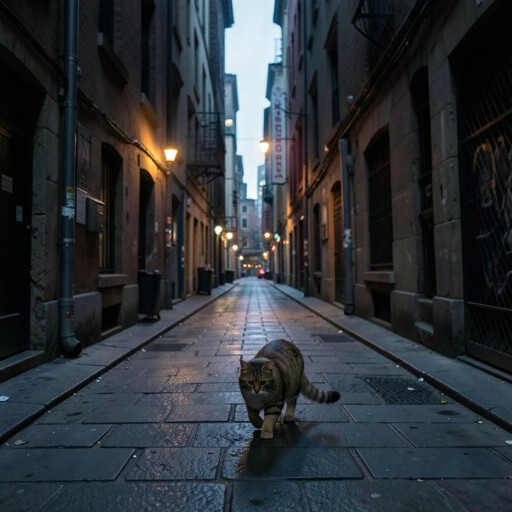

0.5617805250003585

In [10]:
generate(pipeline, replace(config, prompt="A cat meanders down a dimly lit alleyway in a large city.", seed=3))

# 3. Engine Caching
Building the <span style='color: #76B900'>TensorRT-RTX</span> engine is the slowest part of startup. With _Engine Caching_, Torch-TensorRT stores built engines on disk and, on later runs with the same model and shape, loads the cached engine and refits it with the current weights and FP8 scales instead of building a new one.

Refitting requires refittable engines, which take longer to build than the immutable-weight engines used above. The first run pays this one-time cost to populate the cache; the second run reuses the cached engine.

In [ ]:
printmd("**First run**: building the engine and populating the engine cache")
pipeline, engine_cache_cold_times = prepare_pipeline(
    config=config,
    enable_engine_cache=True,  #### Enabled engine cache here ####
)

In [ ]:
printmd("**Second run**: reusing the cached engine")
pipeline, engine_cache_warm_times = prepare_pipeline(
    config=config,
    enable_engine_cache=True,
)

printmd(
    markdown_bold_green_format("Engine Cache")
    + f" `torch_tensorrt.dynamo.compile` time: {engine_cache_warm_times['compile']:.2f} seconds, "
    f"a **{initial_compile_times['compile'] / engine_cache_warm_times['compile']:.2f}x** Improvement over the Quickstart"
)

In [ ]:
generate(pipeline, replace(config, prompt="A dramatic cityscape from a dazzling angle", seed=5))

# 4. Weight Streaming
In cases where GPU memory is limited, _Weight Streaming_ keeps only part of the transformer weights resident in GPU memory and streams the rest from host memory during execution. The budget is a fraction in `[0, 1]` of the streamable weights: `0` streams the most weights (maximal offloading), `1` keeps all streamable weights on the GPU, and `None` disables weight streaming. Lower budgets save more memory at the cost of additional memory transfers, which add overhead to the end-to-end time.

In [11]:
pipeline, _ = prepare_pipeline(
    config=config,
    weight_streaming_budget=0.3,  #### Enabled weight streaming here ####
)

Initializing FLUX.2 [klein] 4B with an FP8 <span style='color: #76B900; font-weight: bold'>TensorRT-RTX</span> transformer with **Runtime Cache** + **Weight Streaming** (30% budget)...

**Loading the Diffusers pipeline**...

Inserted 409 quantizers


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

**Exporting and compiling the transformer**...

  0%|          | 0/1 [00:00<?, ?it/s]

**Step 1** `torch.export` time: 2.30 seconds

**Step 2** `torch_tensorrt.dynamo.compile` time: 40.08 seconds

<span style='color: #76B900; font-weight: bold'>JIT Compilation</span> + first transformer execution time: 0.61 seconds

**Weight streaming**: 1.14 GiB of 3.79 GiB of transformer weights kept on the GPU

**Prompt**: A serene forest scene


[I] Starting image generation with dimensions: 1024 x 1024 and 4 denoising iterations
[I] Using seed 11


  0%|          | 0/4 [00:00<?, ?it/s]

**Generated Image(s) in 0.61s**

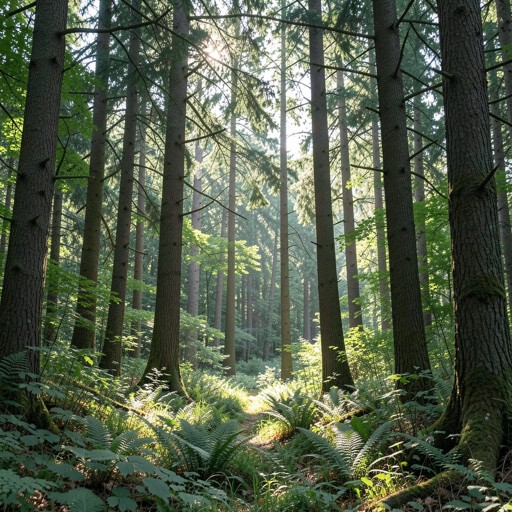

**GPU memory in use** after generation: 11.55 GB with weight streaming vs. 13.81 GB in the Quickstart

**Generation time**: 0.61s with weight streaming vs. 0.61s in the Quickstart

In [12]:
weight_streaming_seconds = generate(pipeline, replace(config, prompt="A serene forest scene", seed=11))
weight_streaming_memory_gb = gpu_memory_used_gb()

printmd(
    f"**GPU memory in use** after generation: {weight_streaming_memory_gb:.2f} GB with weight streaming "
    f"vs. {quickstart_memory_gb:.2f} GB in the Quickstart"
)
printmd(
    f"**Generation time**: {weight_streaming_seconds:.2f}s with weight streaming vs. {quickstart_seconds:.2f}s in the Quickstart"
)

## Cleanup

In [13]:
pipeline.cleanup()
pipeline = None